# Four-channel AD3552R DAC: circuit design and verification tutorial

**Standalone design notebook | Two AD3552R devices | Four 16-bit outputs | ADA4807-1 transimpedance stages | FPGA / LQG actuation**

This notebook assembles the **complete reference-level circuit design** developed alongside the levitated-optomechanics LQG notebook. It contains the circuit drawings, signal and pin mappings, transimpedance amplifier (TIA) connections, supply and reference networks, example register settings, update timing, bill of materials, numerical checks, and a bring-up checklist.

**Output stage: the manufacturer's ADA4807-1 reference circuit.** Every DAC output uses the amplifier and component values with which the AD3552R data sheet measures its dynamic specifications: an **ADA4807-1** TIA closed through the on-chip `RFB2` resistor, an **8.2 pF NP0 feedback capacitor**, and `VCM` decoupled with **0.1 uF**. Section 7.1 models this stage numerically: bandwidth, phase margin, slew rate and settling.

**Design status: illustrative engineering reference, not a fabrication-ready schematic.** The graphics show electrical intent and matching net names, not an editable, electrical-rule-checked CAD netlist. The feedback capacitor is the manufacturer's characterisation value; it must still be confirmed on the actual layout and load before hardware is built.

This is **a separate notebook**: it needs only NumPy and Matplotlib for its calculations. The LQG notebook (`pylqg_tutorial.ipynb`, Section 12) uses the same ADA4807-1 stage as part of its plant model.

## 1. Design requirements, provenance, and limitations

### What came from the earlier numerical notebook

The original design study considers a plant sensed every $T_s=64$ ns and a **lifted, multirate LQR** actuator that only changes its commanded voltage every $N=24$ fast samples. The proposed hardware is **two AD3552R devices**, each with two DAC channels, and a common update strobe. In that source notebook, the ADC latency (96 ns), an idealised quad-SPI write, a 20 ns update allowance, and a 100 ns DAC settling allowance add to about 398 ns. Those numbers are **assumptions in a model**, not verified bench results.

### Independently checked against manufacturer documentation

- The **AD3552R is a dual-channel, 16-bit current-output DAC**, and **requires external TIAs** to generate voltages. It provides internal selectable gain feedback resistors. [AD3552R datasheet, Rev. B](https://www.analog.com/media/en/technical-documentation/data-sheets/ad3552r.pdf), pp. 1, 26-27 and 68.
- The **RFB2** resistor and **output-range selection code `0b011` per channel** are paired for the nominal **-5 V to +5 V** span (datasheet Table 8, p. 26; register map, p. 57).
- Both chips can use **quad SPI** and a **shared, active-low LDAC** to command output updates (datasheet pp. 34-37). That does **not** establish a guaranteed 5 ns cross-chip output skew.
- **100 ns large-signal settling** is quoted **to 0.1%**, not to 16-bit resolution (datasheet p. 1), and it is measured in the **0 V to 5 V range** (`RFB1`, Table 3). The **±5 V range uses `RFB2`, twice the resistance**, so the same amplifier and capacitor settle about twice as slowly (Section 7.1: about 180 ns to 0.1%).
- **The data sheet's AC characteristics are "measured with the ADA4807-1 external amplifier"** (Table 3). Its plots give the component values: **C_FB = 8.2 pF** for the 2.5 V, 5 V and ±5 V ranges and 6.8 pF for the 10 V range, with **R_LOAD = 1 kOhm** (Figures 53-59). Figure 59 gives the resulting slew rate, about **180 V/us** in the ±5 V range at 25 C. This is the reference circuit used here; Figure 94 gives its topology and decoupling.
- The **ADA4807-1** (ADA4807 data sheet) has 180 MHz small-signal bandwidth (G = +1), 225 V/us slew rate, 1 pF + 1 pF input capacitance, a **2.7 V to 11 V total supply**, rail-to-rail output (within about 40-100 mV of the rails into 1 kOhm), and about 50 mA / 60 mA linear output current (source / sink).

**Not specified by the available sources:** actual FPGA connector/pin assignments, load impedance and capacitance, the DAC's `IOUT` pin capacitance (needed for an exact stability calculation), exact regulator part numbers, and measured DAC-to-actuator settling. These remain design decisions or measurements, not facts. The 8.2 pF feedback capacitor is the manufacturer's *characterisation* value; Section 7.1 shows that it is robust to the unknown capacitance, but it should still be confirmed on the real board.

## 2. Top-level architecture

| Block | Reference choice | Function |
|---|---|---|
| FPGA | Existing LQG FPGA / 1.8 V-compatible I/O bank | Computes four actuator codes and drives SPI + LDAC |
| U1, U2 | **2 x AD3552R** | Two 16-bit current DACs per chip |
| U3-U6 | **4 x ADA4807-1** (manufacturer's characterisation amplifier) | External TIA for each current output, C_FB = 8.2 pF |
| Reference | **2.5 V**, e.g. ADR4525, external option | DAC reference; internal 2.5 V is also possible |
| Digital rails | **1.8 V** (`DVDD`, `VLOGIC`) | Core logic and FPGA-compatible interface |
| Analog rail | **+5 V** (`AVDD`) | DAC analog supply |
| Op-amp rails | **+5 V / -5 V** (10 V total; ADA4807-1 maximum 11 V) | Output swing about +/-4.9 V: the +/-5 V range is usable except its outer ~3% (clamp at +/-4.85 V) |
| DAC update | Common active-low **LDAC** | Synchronises conversion of staged codes |
| Output load | **Not yet specified** | Must be known before terminating/buffering the analog output |

**Output assignment:** U1/CH0 = OUT0, U1/CH1 = OUT1, U2/CH0 = OUT2, U2/CH1 = OUT3. A three-axis experiment may leave OUT3 spare.

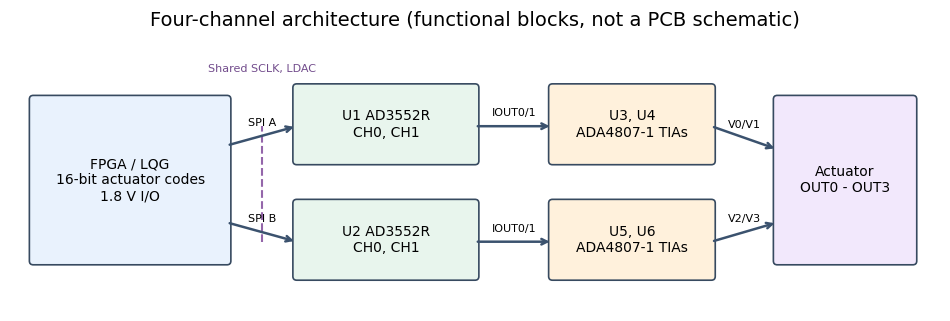

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.set_xlim(0, 12); ax.set_ylim(0, 3.5); ax.axis('off')
def block(x,y,w,h,lab,color):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.05',
                                fc=color,ec='#374a60',lw=1.2))
    ax.text(x+w/2,y+h/2,lab,ha='center',va='center',fontsize=10)
def conn(a,b,lab=''):
    ax.annotate('',xy=b,xytext=a,arrowprops=dict(arrowstyle='->',lw=1.8,color='#3b526e'))
    if lab: ax.text((a[0]+b[0])/2,(a[1]+b[1])/2+.13,lab,ha='center',fontsize=8)
block(.3,.65,2.5,2.1,'FPGA / LQG\n16-bit actuator codes\n1.8 V I/O','#e9f2fd')
block(3.7,1.95,2.3,.95,'U1 AD3552R\nCH0, CH1','#e8f5ed')
block(3.7,.45,2.3,.95,'U2 AD3552R\nCH0, CH1','#e8f5ed')
block(7.0,1.95,2.05,.95,'U3, U4\nADA4807-1 TIAs','#fff1dc')
block(7.0,.45,2.05,.95,'U5, U6\nADA4807-1 TIAs','#fff1dc')
block(9.9,.65,1.75,2.1,'Actuator\nOUT0 - OUT3','#f2e8fc')
for a,b,l in [((2.8,2.15),(3.7,2.4),'SPI A'),((2.8,1.15),(3.7,.9),'SPI B'),
              ((6,2.4),(7,2.4),'IOUT0/1'),((6,.9),(7,.9),'IOUT0/1'),
              ((9.05,2.4),(9.9,2.1),'V0/V1'),((9.05,.9),(9.9,1.15),'V2/V3')]:conn(a,b,l)
ax.plot([3.25,3.25],[.9,2.4],ls='--',color='#9466aa'); ax.text(3.25,3.1,'Shared SCLK, LDAC',fontsize=8,ha='center',color='#724c8c')
ax.set_title('Four-channel architecture (functional blocks, not a PCB schematic)',fontsize=14,pad=12)
plt.show()

## 3. Digital circuit: FPGA to two AD3552Rs

The diagram below is the two-chip interface drawing from the prior design. **Wires with matching net names are electrically connected**; abbreviated bundle lines represent groups of nets. It is a block-level schematic, *not* an FPGA-board-specific connector diagram.

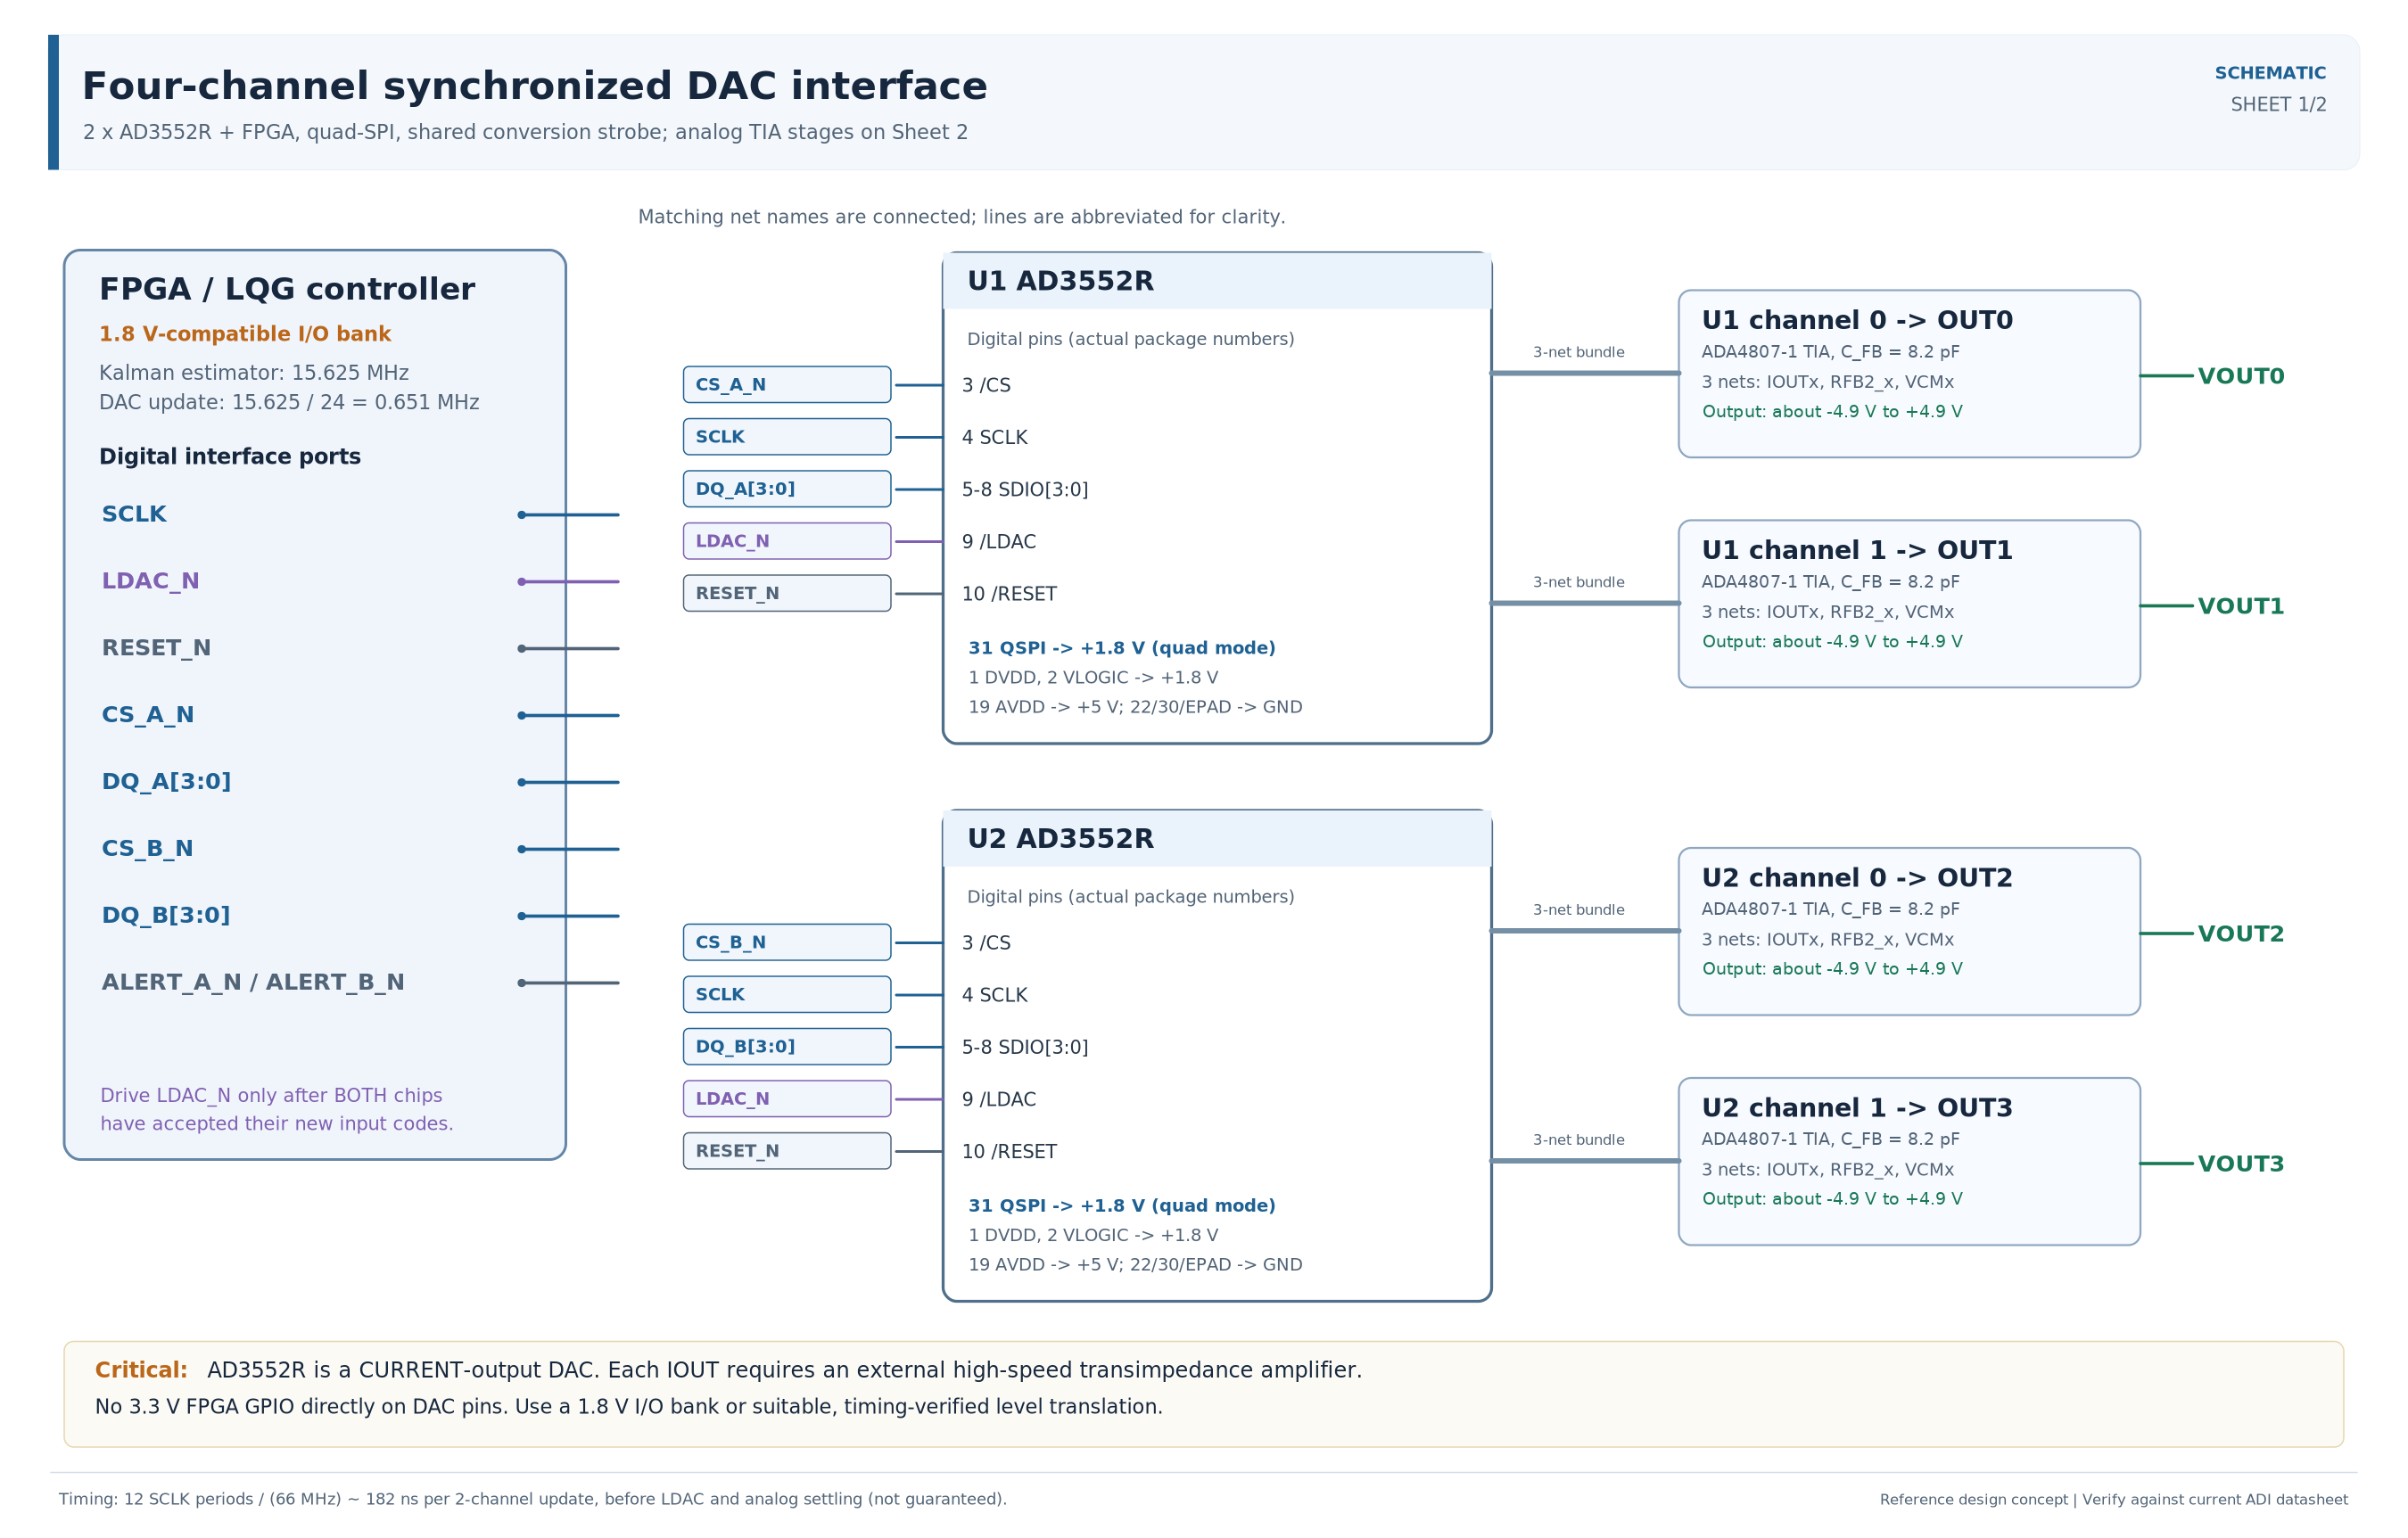

*Sheet 1: dual-device quad-SPI interface and four synchronized outputs (ADA4807-1 TIA stages detailed on Sheet 2)*

### Signal-by-signal wiring

| Net | FPGA side | DAC U1 | DAC U2 | Why it matters |
|---|---|---|---|---|
| `SCLK` | Clock output, 1.8 V | Pin **4** | Pin **4** | Shared serial clock |
| `CS_A_N` | Dedicated output | Pin **3** | - | Select U1, active low |
| `CS_B_N` | Dedicated output | - | Pin **3** | Select U2, active low |
| `DQ_A[0:3]` | Four bidirectional-capable or driven FPGA signals | Pins **5,6,7,8** | - | Quad-SPI lanes for U1 |
| `DQ_B[0:3]` | Four separate FPGA signals | - | Pins **5,6,7,8** | Quad-SPI lanes for U2 |
| `LDAC_N` | Common timing output | Pin **9** | Pin **9** | Assert **after** both chips contain valid new input codes |
| `RESET_N` | Shared or individually gated output | Pin **10** | Pin **10** | Reset; hold inactive high when operating |
| `ALERT_A_N` | Status input | Pin **11** | - | Error indication from U1 |
| `ALERT_B_N` | Status input | - | Pin **11** | Error indication from U2 |
| `QSPI` | Static strap, not an SPI data lane | Pin **31**, high | Pin **31**, high | Selects quad mode |
| `DVDD` | Local regulator | Pin **1**, +1.8 V | Pin **1**, +1.8 V | Core supply |
| `VLOGIC` | Logic supply | Pin **2**, +1.8 V | Pin **2**, +1.8 V | Digital I/O levels |
| `AVDD` | Analog supply | Pin **19**, +5 V | Pin **19**, +5 V | Analog supply |
| `DGND`, `AGND`, exposed pad | Ground plane | Pins **30**, **22**, EPAD | Same | Common return, with local noise-aware routing |

**Electrical interface rule:** the DAC logic pins are intended for roughly 1.2 V / 1.8 V logic. A 3.3 V FPGA bank **must not connect directly**. Select a 1.8 V I/O bank or qualify an appropriate voltage translator against the SPI timing. The CS signals are separate, but both chips may be written concurrently using two independent quad-data groups and a shared SCLK.

**Clock-polarity configuration:** the AD3552R supports SPI modes 0 and 3 in SDR; check the CPOL/CPHA constraints in datasheet p. 34. Sample/data phase turnaround and drive strength are not optional details for readback.

## 4. Complete AD3552R package pin map (repeat for U1 and U2)

The following is the **32-pin LFCSP** device pinout from the AD3552R Rev. B datasheet, Figure 13 and Table 7 (pp. 12-13). It is not a board connector pinout.

| Pin | Name | Reference connection or role |
|---:|---|---|
| 1 | DVDD | +1.8 V, local decoupling |
| 2 | VLOGIC | +1.8 V, local decoupling |
| 3 | /CS | Independent per-device FPGA select |
| 4 | SCLK | Shared FPGA clock |
| 5 | SDI/SDIO0 | Quad data lane 0 |
| 6 | SDO/SDIO1 | Quad data lane 1 |
| 7 | SDIO2 | Quad data lane 2 |
| 8 | SDIO3 | Quad data lane 3 |
| 9 | /LDAC | Shared active-low DAC update |
| 10 | /RESET | FPGA reset or tie inactive to VLOGIC as appropriate |
| 11 | /ALERT | Device alert, separate inputs |
| 12 | PCAP1 | DAC channel 1 noise-reduction capacitor to AVDD |
| 13 | NCAP1 | DAC channel 1 noise-reduction capacitor to AGND |
| 14 | VCM1 | Reference/common-mode for channel 1 TIA non-inverting input |
| 15 | IOUT1 | Current-output pin -> channel 1 TIA inverting input |
| 16 | RFB1_1 | Unused for selected RFB2 configuration |
| 17 | RFB2_1 | Channel 1 amplifier feedback/output node |
| 18 | RFB4_1 | Unused for selected RFB2 configuration |
| 19 | AVDD | +5 V analog supply |
| 20 | VREF | 2.5 V reference input in external-reference mode |
| 21 | CVREF | Reference decoupling capacitor to AGND |
| 22 | AGND | Analog ground |
| 23 | RFB4_0 | Unused for selected RFB2 configuration |
| 24 | RFB2_0 | Channel 0 amplifier feedback/output node |
| 25 | RFB1_0 | Unused for selected RFB2 configuration |
| 26 | IOUT0 | Current-output pin -> channel 0 TIA inverting input |
| 27 | VCM0 | Reference/common-mode for channel 0 TIA non-inverting input |
| 28 | NCAP0 | DAC channel 0 noise-reduction capacitor to AGND |
| 29 | PCAP0 | DAC channel 0 noise-reduction capacitor to AVDD |
| 30 | DGND | Digital ground |
| 31 | QSPI | Strap high for quad SPI |
| 32 | DNC | **Do not connect**; leave floating |
| EPAD | Exposed pad | Connect to ground plane per package/layout guidance |

**Do not interchange** `IOUT`, `RFB2`, and `VCM`: they have different electrical roles. Leave unused feedback resistor pins unconnected, rather than tying them to ground.

## 5. Analog circuit: one channel, repeated four times

The second diagram shows the **manufacturer's ADA4807-1 transimpedance stage** and the per-chip rails. **Every `IOUTx` needs its own external TIA**. A schematic label reading `VOUTx` denotes the *amplifier output*, not a voltage generated directly by the DAC IC.

Compared with the earlier AD8065 concept, three things changed: the amplifier (ADA4807-1, so **+/-5 V rails** instead of +/-12 V), the **feedback capacitor** (now the data sheet's 8.2 pF instead of "to be tuned"), and the **`VCM` connection** (now direct, with 0.1 uF to ground, as in data sheet Figure 94). The earlier 3.3 kOhm series resistor came from data sheet Figure 95, which shows how to *combine two DAC channels into one amplifier*; it is not part of the single-channel circuit.

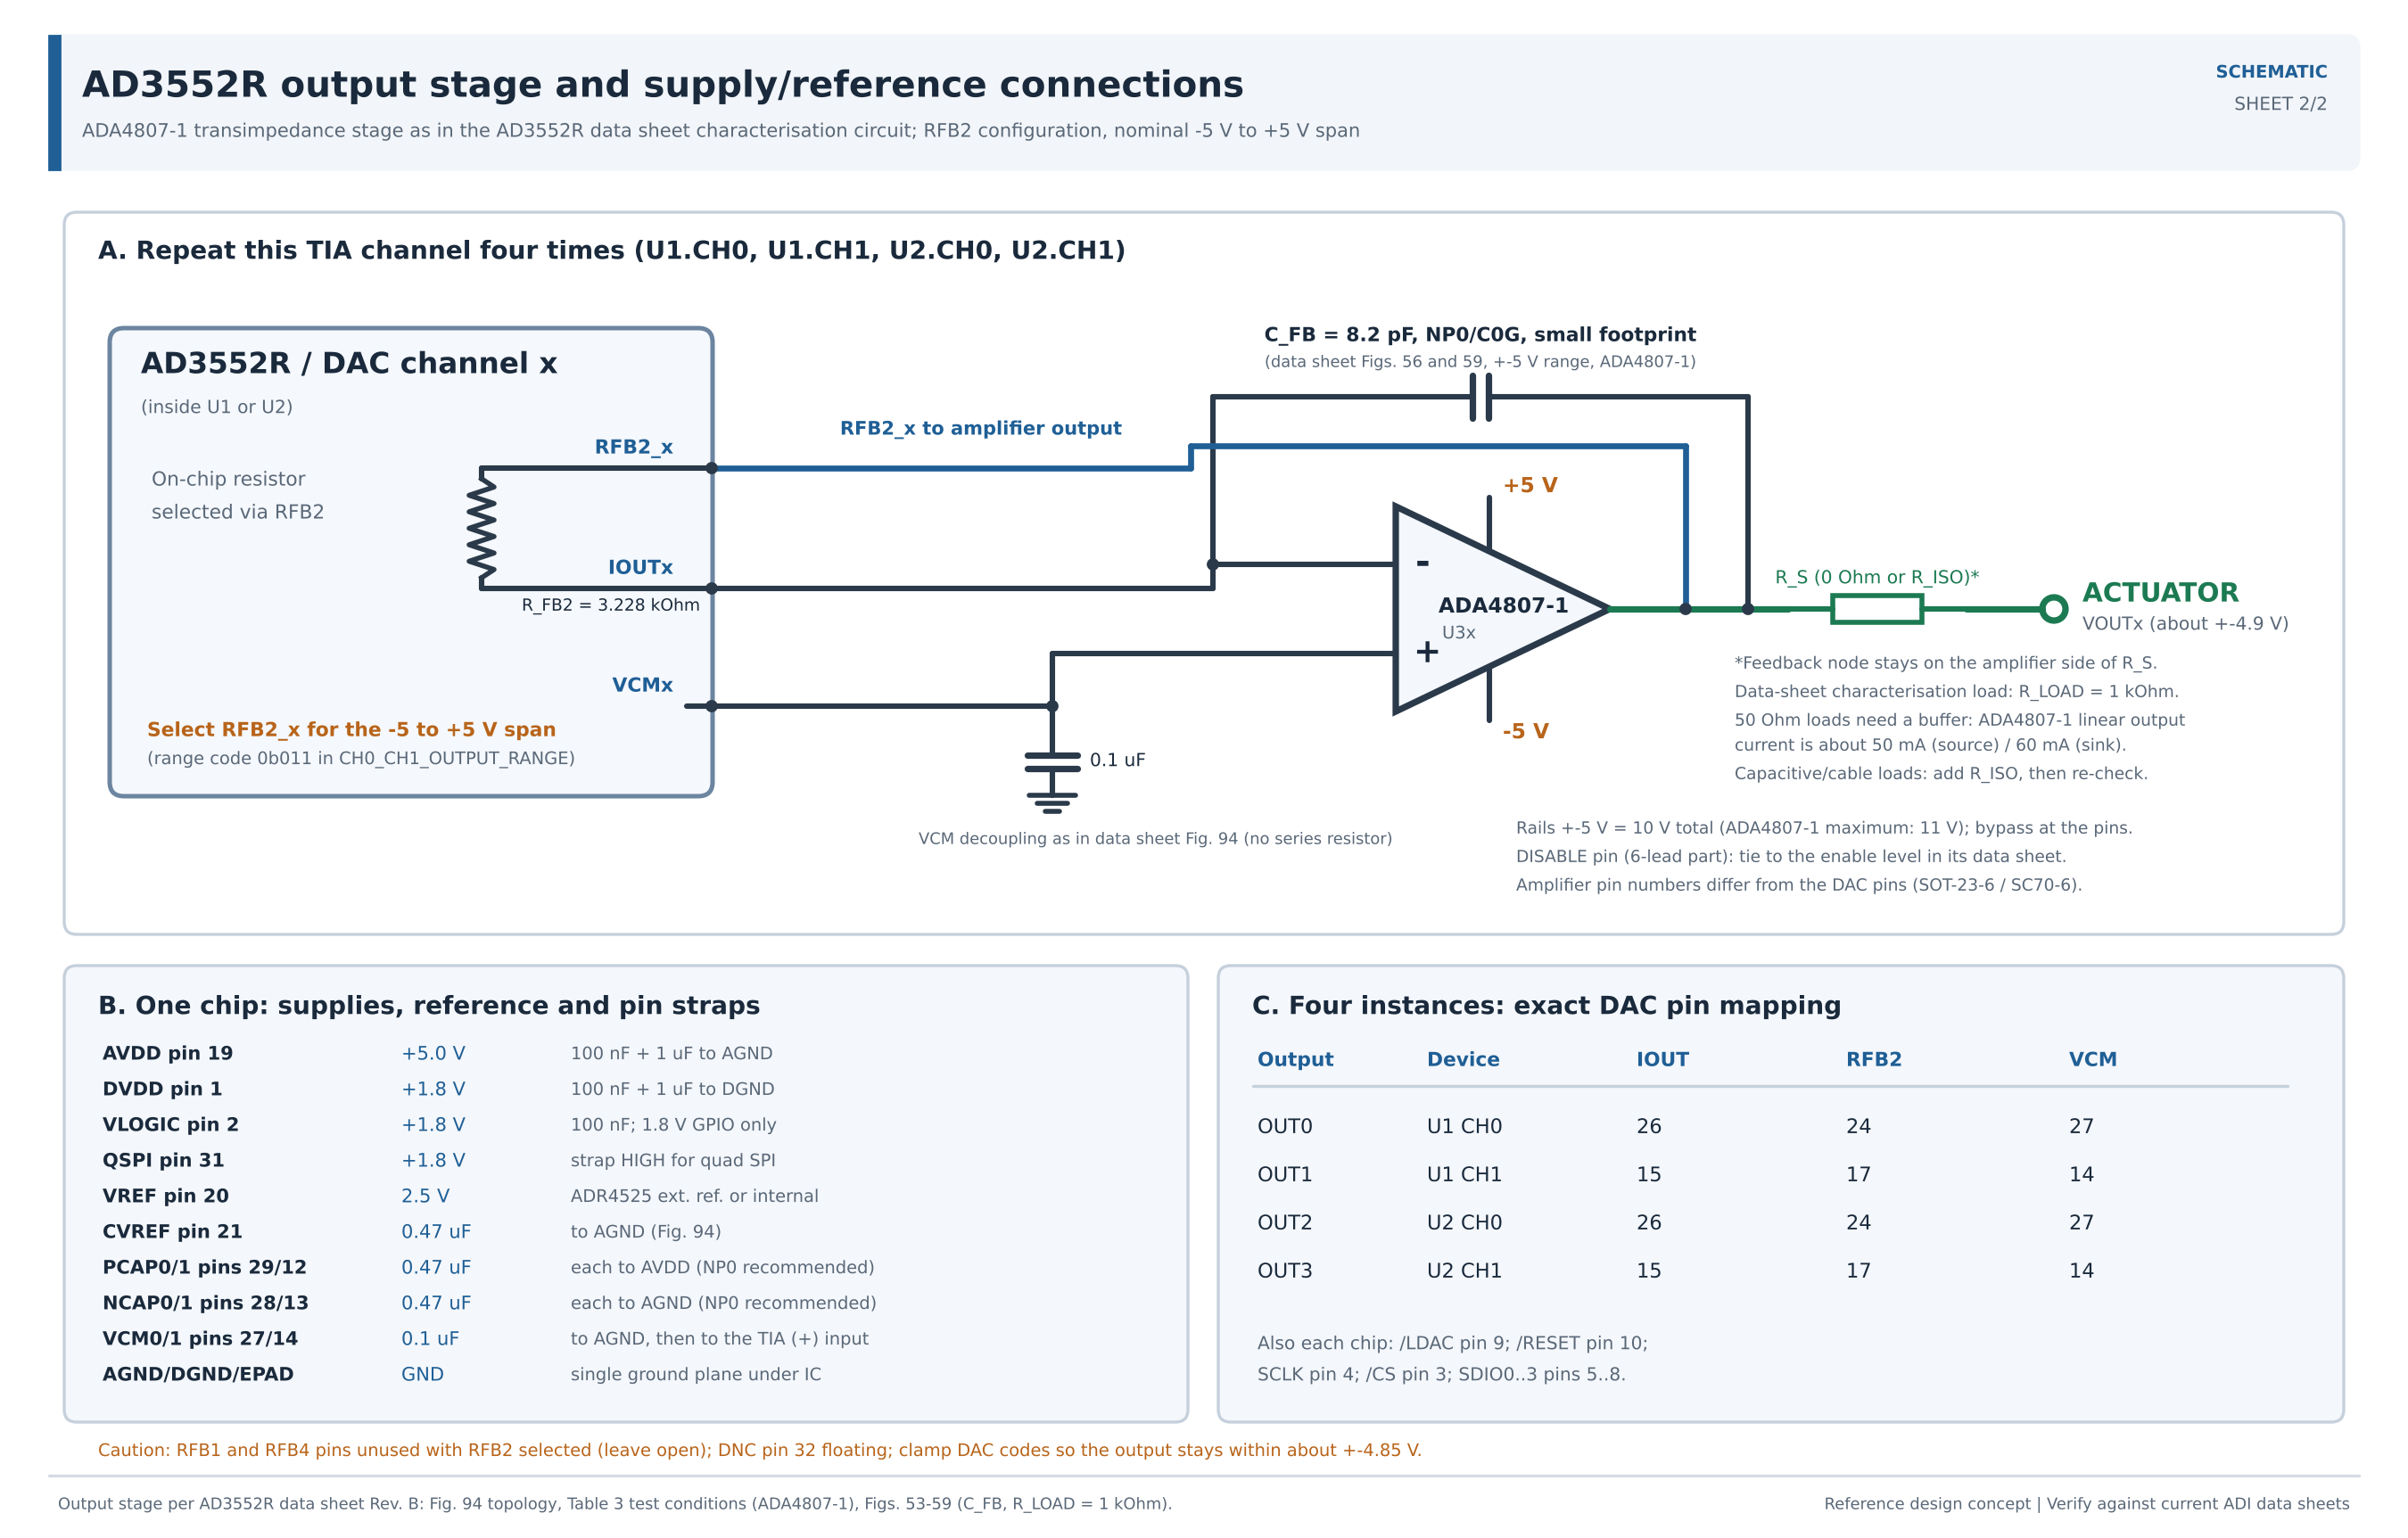

*Sheet 2: AD3552R current-to-voltage channel (ADA4807-1 reference circuit) and power/reference connections*

### One channel as an explicit electrical connection list

1. `IOUTx` (U1/U2, pin 26 or 15) -> **ADA4807-1 inverting (-) input**, with the shortest and thinnest practical trace. The data sheet's layout guidelines (p. 69) point out that parasitic capacitance on this line increases settling time and that it is a high-impedance node prone to pick-up.
2. `RFB2_x` (pin 24 or 17) -> **ADA4807-1 output, before any output series resistor**. This closes the feedback path through the DAC's on-chip **3.228125 kOhm** (nominal) resistor.
3. `VCMx` (pin 27 or 14) -> **ADA4807-1 non-inverting (+) input directly**, with **0.1 uF** from that node to ground (data sheet Figure 94). No series resistor: the 3.3 kOhm resistors in data sheet Figure 95 belong to the two-channels-into-one-amplifier configuration.
4. `C_FB` = **8.2 pF, NP0/C0G**, from the **inverting input to the amplifier output**: the value with which the data sheet characterises the +/-5 V range using the ADA4807-1 (Figures 56, 59). The data sheet asks for NP0 dielectric on capacitors in the output-voltage path and a small footprint for this one (pp. 68-69).
5. ADA4807-1 supply pins -> **+5 V and -5 V**, locally bypassed. The 6-lead ADA4807-1 also has a **DISABLE** pin: tie it to the enable level given in the ADA4807 data sheet, never leave it floating. Check the **specific package pinout** (SOT-23-6 or SC70-6): the DAC pin numbers do not apply to the amplifier.
6. Amplifier output -> output connector, **possibly via a series resistor** selected for the actual cable/load (`R_ISO` for capacitive loads). **The feedback node stays on the amplifier side of this resistor** unless the circuit is explicitly redesigned.

The fundamental transfer law (datasheet p. 27) is

$$V_{\mathrm{OUT}} = V_{\mathrm{CM}} - R_{\mathrm{FB}} I_{\mathrm{OUT}}.$$

The DAC's register-controlled bipolar offset and gain create a nominal $-5$ V to $+5$ V output with **RFB2** connected, despite $V_{CM}\approx 2.5$ V. The exact end points include roughly 3% overrange (-5.165 V / +5.166 V, Table 8). **With +/-5 V amplifier rails the ADA4807-1 output stops about 0.1 V short of each rail**, so the extreme codes cannot be reproduced: clamp commands in firmware to about +/-4.85 V, and calibrate rather than assume an ideal line.

**Potential design issue:** an optional 49.9 Ohm *series* resistor is shown in earlier drawings as a line-matching part. If the receiving instrument has a 50 Ohm input termination, there is substantial voltage division and a drive current the ADA4807-1 cannot supply (Section 10). It is **not** correct to promise +/-5 V at the actuator terminal merely because the DAC range is configured to +/-5 V.

## 6. DAC range registers and the voltage transfer function

In the datasheet's **predefined output-range** table, `0b011` selects **-5 V to +5 V** *when* the selected channel's output amplifier feedback uses `RFB2_x`. The upper nibble of the `CH0_CH1_OUTPUT_RANGE` register is for channel 1 and the lower nibble for channel 0, so a natural starting write is:

`CH0_CH1_OUTPUT_RANGE` at address **0x19** <- **0x33** (both channels set to 0b011).

This is a **register-level starting point**, not an entire verified firmware driver. The external/internal reference selection, channel state, LDAC masks, data-address ordering, and error/status bits also require deliberate configuration. Use the current datasheet register definitions rather than copying an undocumented register dump.

For first-pass scaling, use $\Delta V\approx(10\,\mathrm{V})/2^{16}$; with a bipolar ideal midscale mapping, $V\approx -5 + 10 D/(2^{16}-1)$ for unsigned code $D$. **This pedagogical formula is not the exact AD3552R transfer function**: the datasheet's actual offset/gain terms and overrange alter endpoints (its p. 27 equation should be used for an accurate code-to-voltage model).

Ideal +/-5 V LSB = 152.588 uV, rms quantization noise = 44.05 uV
  code 0x0000 (    0) -> about -5.00000 V
  code 0x4000 (16384) -> about -2.49996 V
  code 0x8000 (32768) -> about +0.00008 V
  code 0xC000 (49152) -> about +2.50011 V
  code 0xFFFF (65535) -> about +5.00000 V


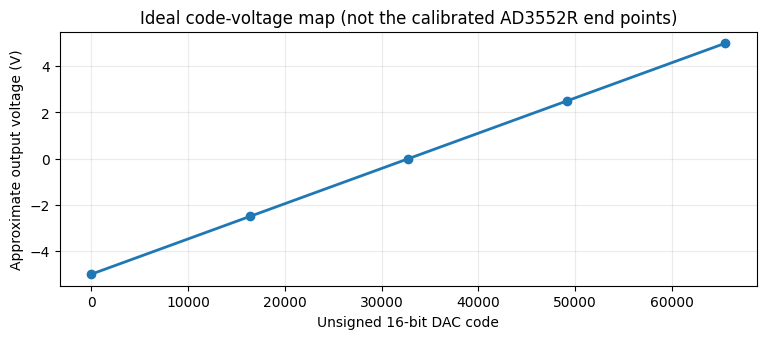

In [2]:
# Simple idealised code-to-voltage conversion to size the feedback signals.
Vmin, Vmax = -5.0, 5.0
n_bits = 16
lsb = (Vmax - Vmin) / 2**n_bits
codes = np.array([0, 16384, 32768, 49152, 65535])
volts = Vmin + codes * (Vmax - Vmin) / 65535
print(f'Ideal +/-5 V LSB = {lsb*1e6:.3f} uV, rms quantization noise = {lsb/np.sqrt(12)*1e6:.2f} uV')
for d, v in zip(codes, volts):
    print(f'  code 0x{d:04X} ({d:5d}) -> about {v:+.5f} V')
fig,ax=plt.subplots(figsize=(9,3.3))
ax.plot(np.linspace(0,65535,500),Vmin+(Vmax-Vmin)*np.linspace(0,65535,500)/65535,lw=2)
ax.scatter(codes,volts,zorder=3)
ax.set(xlabel='Unsigned 16-bit DAC code',ylabel='Approximate output voltage (V)',
       title='Ideal code-voltage map (not the calibrated AD3552R end points)')
ax.grid(alpha=.25)
plt.show()

## 7. Current-output DAC intuition and compensation

The DAC uses a programmable current source/sink rather than a direct voltage driver. The amplifier holds its inverting input close to the `VCM` level and converts DAC current to a voltage via the internal selected feedback resistor. This is why a simple output-voltage buffer is **not** an adequate replacement for the TIA.

- `RFB1` nominal **1.610938 kOhm**: used for the 2.5 V and 5 V spans.
- `RFB2` nominal **3.228125 kOhm**: used for the **10 V** and **+/-5 V** spans.
- `RFB4` nominal **6.488125 kOhm**: used for the **+/-10 V** span.

**Why the feedback capacitor is needed.** The amplifier sees the DAC's output capacitance, its own input capacitance and the layout capacitance at its inverting input, $C_{in}$, in series with the feedback resistor. Without $C_{FB}$ this forms a pole at $1/(R_FC_{in})$, far below the amplifier's crossover frequency, which eats almost all of the loop's phase margin, so the stage rings or oscillates. $C_{FB}$ adds a zero at $1/(R_FC_{FB})$ that restores the phase. The price is a dominant time constant $R_FC_{FB}$: 26 ns for RFB2 with 8.2 pF.

**The reference values.** The data sheet characterises the ADA4807-1 with **8.2 pF** (2.5 V, 5 V, ±5 V ranges) and **6.8 pF** (10 V range), R_LOAD = 1 kOhm (Figures 53-59). Those are the values used here. A smaller capacitor would be faster but is outside the characterised conditions. **Do not place an arbitrarily large capacitor across the TIA** in a time-critical LQG loop: every extra picofarad slows the actuator by about 3 ns (R_F = 3.2 kOhm).

The ADA4807-1's 180 MHz bandwidth does **not** mean the DAC+TIA settles in a few nanoseconds: the stage is set by $R_FC_{FB}$ and, for large steps, by the slew rate. The next subsection quantifies this.

### 7.1 A numerical model of the ADA4807-1 stage

A single-pole model of the op-amp, $A(s)=A_0\omega_p/(s+\omega_p)$ with gain-bandwidth $\omega_t=A_0\omega_p$, closed around $Z_F=R_F\,\|\,C_{FB}$ with $C_{in}$ at the inverting node, gives the transfer function from the voltage the DAC code asks for, $V_{cmd}=-R_FI_{OUT}$, to the actual output:

$$
H(s)=\frac{V_{OUT}}{V_{cmd}}=\frac{1}{(1+sR_FC_{FB})+\big(1+sR_F(C_{FB}+C_{in})\big)\dfrac{s+\omega_p}{\omega_t}} .
$$

The loop gain is $T=A\beta$ with $\beta=(1+sR_FC_{FB})/(1+sR_F(C_{FB}+C_{in}))$. Large steps are additionally limited by the slew rate, so the code below also integrates the circuit equations with the output rate clipped to ±SR and the output clamped to the swing.

Two inputs are **assumptions**, because neither data sheet states them: the gain-bandwidth product (taken as the 180 MHz unity-gain bandwidth) and $C_{in}$ (10 pF nominal: 2 pF amplifier input plus the DAC pin and layout). The model is checked against the one configuration for which the data sheet gives settling times (0-5 V range, RFB1, 8.2 pF).

Small-signal behaviour of the +/-5 V stage (RFB2) versus C_FB and the unknown C_in:
  C_FB  C_in     -3 dB  peaking  phase margin
 0.0pF   5pF    64.8MHz   12.7dB        13.3deg
 0.0pF  10pF    46.1MHz   15.7dB         9.5deg
 0.0pF  20pF    32.7MHz   18.6dB         6.7deg
 4.7pF   5pF    11.1MHz   -0.0dB        86.5deg
 4.7pF  10pF    11.8MHz    0.0dB        83.1deg
 4.7pF  20pF    13.0MHz   -0.0dB        76.8deg
 8.2pF   5pF     6.1MHz    0.0dB        88.8deg
 8.2pF  10pF     6.3MHz    0.0dB        87.7deg
 8.2pF  20pF     6.5MHz   -0.0dB        85.4deg

Check against the data sheet (0-5 V range, RFB1, C_FB = 8.2 pF, 2 V step, system slew ~150 V/us):
   model: 57 ns to 1%, 85 ns to 0.1%   | data sheet Table 3: 75 ns, 100 ns

This design (+/-5 V range, RFB2, C_FB = 8.2 pF, ~180 V/us, +/-5 V rails -> swing +/-4.9 V):
    0.06 V step:  119 ns to 1%,  177 ns to 0.1%
    2.00 V step:  119 ns to 1%,  177 ns to 0.1%
    9.00 V step:  113 ns to 1%,  171 ns to 0.1%
   R_F*C_FB = 26.5 ns; the 

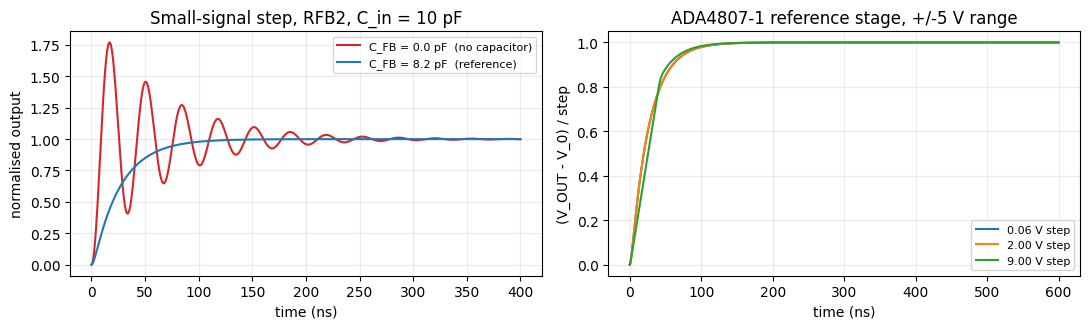

In [3]:
# Self-contained TIA model (the same equations as pylqg.actuator in the LQG notebook)
RFB = {"RFB1": 1610.938, "RFB2": 3228.125}
A0 = 10 ** (130 / 20)                       # ADA4807-1 open-loop gain, 130 dB typ

def H_den(RF, CF, Cin, GBW):
    wt = 2 * np.pi * GBW; wp = wt / A0
    return np.polyadd([RF * CF, 1.0], np.polymul([RF * (CF + Cin), 1.0], [1.0, wp]) / wt)

def freq_metrics(RF, CF, Cin, GBW=180e6):
    f = np.logspace(3, 11, 40001); s = 2j * np.pi * f
    h = 1 / np.polyval(H_den(RF, CF, Cin, GBW), s); h /= abs(h[0])
    wt = 2 * np.pi * GBW
    T = wt / (s + wt / A0) * (1 + s * RF * CF) / (1 + s * RF * (CF + Cin))
    i = np.argmax(np.abs(T) < 1)
    return f[np.argmax(np.abs(h) < 1 / np.sqrt(2))], 20 * np.log10(np.abs(h).max()), 180 + np.degrees(np.angle(T[i]))

def step(RF, CF, Cin, v0, v1, SR=np.inf, vmin=-np.inf, vmax=np.inf, GBW=180e6, t_end=600e-9, dt=0.05e-9):
    """Large-signal step: RK4 on (v_minus, v_out) with slew-rate and swing limits."""
    wt = 2 * np.pi * GBW; wp = wt / A0
    def rhs(x, vcmd):
        vm, vo = x
        dvo = np.clip(-wt * vm - wp * vo, -SR, SR)
        if (vo >= vmax and dvo > 0) or (vo <= vmin and dvo < 0): dvo = 0.0
        dvm = (-vcmd / RF - (vm - vo) / RF + CF * dvo) / (Cin + CF)
        return np.array([dvm, dvo])
    x = np.array([-v0 / A0, v0]); t = np.arange(0, t_end, dt); y = np.empty(len(t))
    for k in range(len(t)):
        y[k] = x[1]
        k1 = rhs(x, v1); k2 = rhs(x + dt / 2 * k1, v1); k3 = rhs(x + dt / 2 * k2, v1); k4 = rhs(x + dt * k3, v1)
        x = x + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4); x[1] = min(max(x[1], vmin), vmax)
    return t, y

def settle(t, y, v0, v1, tol):
    bad = np.where(np.abs(y - v1) > tol * abs(v1 - v0))[0]
    return t[min(bad[-1] + 1, len(t) - 1)] if len(bad) else 0.0

print("Small-signal behaviour of the +/-5 V stage (RFB2) versus C_FB and the unknown C_in:")
print(f"{'C_FB':>6s} {'C_in':>5s} {'-3 dB':>9s} {'peaking':>8s} {'phase margin':>13s}")
for CF in (0.0, 4.7e-12, 8.2e-12):
    for Cin in (5e-12, 10e-12, 20e-12):
        f3, pk, pm = freq_metrics(RFB["RFB2"], CF, Cin)
        print(f"{CF*1e12:4.1f}pF {Cin*1e12:3.0f}pF {f3/1e6:7.1f}MHz {pk:6.1f}dB {pm:11.1f}deg")

print("\nCheck against the data sheet (0-5 V range, RFB1, C_FB = 8.2 pF, 2 V step, system slew ~150 V/us):")
t, y = step(RFB["RFB1"], 8.2e-12, 10e-12, 1.35, 3.35, SR=150e6)
print(f"   model: {settle(t, y, 1.35, 3.35, 1e-2)*1e9:.0f} ns to 1%, {settle(t, y, 1.35, 3.35, 1e-3)*1e9:.0f} ns to 0.1%"
      "   | data sheet Table 3: 75 ns, 100 ns")
print("\nThis design (+/-5 V range, RFB2, C_FB = 8.2 pF, ~180 V/us, +/-5 V rails -> swing +/-4.9 V):")
res = {}
for v0, v1 in ((0.0, 0.06), (-1.0, 1.0), (-4.5, 4.5)):
    t, y = step(RFB["RFB2"], 8.2e-12, 10e-12, v0, v1, SR=180e6, vmin=-4.9, vmax=4.9)
    res[(v0, v1)] = (t, y)
    print(f"   {v1 - v0:5.2f} V step: {settle(t, y, v0, v1, 1e-2)*1e9:4.0f} ns to 1%, {settle(t, y, v0, v1, 1e-3)*1e9:4.0f} ns to 0.1%")
t, y = res[(0.0, 0.06)]                                   # linear (unslewed) response
peak_slope = np.max(np.diff(y)) / (t[1] - t[0]) / 0.06    # peak dV/dt per volt of step
print(f"   R_F*C_FB = {RFB['RFB2']*8.2e-12*1e9:.1f} ns; the linear response's peak slope is {peak_slope/1e6:.0f} V/us per volt,")
print(f"   so only steps larger than about {180e6/peak_slope:.1f} V reach the 180 V/us slew limit")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for CF, col in ((0.0, "C3"), (8.2e-12, "C0")):
    t, y = step(RFB["RFB2"], CF, 10e-12, 0.0, 0.1, t_end=400e-9, dt=0.05e-9)
    ax[0].plot(t * 1e9, y / 0.1, col, label=f"C_FB = {CF*1e12:.1f} pF" + ("  (reference)" if CF else "  (no capacitor)"))
ax[0].set(xlabel="time (ns)", ylabel="normalised output", title="Small-signal step, RFB2, C_in = 10 pF"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.25)
for (v0, v1), (t, y) in res.items():
    ax[1].plot(t * 1e9, (y - v0) / (v1 - v0), label=f"{v1 - v0:.2f} V step")
ax[1].set(xlabel="time (ns)", ylabel="(V_OUT - V_0) / step", title="ADA4807-1 reference stage, +/-5 V range"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.25)
plt.tight_layout(); plt.show()

**What the model says.**

* **Without C_FB the stage is nearly unstable**: 7-13 degrees of phase margin and 13-19 dB of peaking, so the step rings for hundreds of nanoseconds. With the manufacturer's **8.2 pF** the phase margin is **85-89 degrees** whatever the unknown $C_{in}$ (5-20 pF). The response is then essentially first order, with $R_FC_{FB}$ = 26 ns and a -3 dB bandwidth of about 6.3 MHz.
* **The model reproduces the data sheet's large-signal settling** (0-5 V range: about 57 ns / 85 ns against 75 ns / 100 ns) to within 15-25%. It is *pessimistic* for small steps: the data sheet's 60 mV figure (15 ns to 1%) is faster than any linear stage with a 14 ns time constant can be.
* **In the ±5 V range the stage settles in about 180 ns to 0.1%, not 100 ns.** The 100 ns headline belongs to the 0-5 V range with its half-size feedback resistor. Section 9's timing budget uses the ±5 V figure.
* **Slewing is rare.** The linear response is already slower than 180 V/us for any step below about 5.7 V, i.e. more than half of the ±4.9 V output range; the 9 V step above slews only briefly. In closed loop the LQG commands are tens of millivolts (LQG notebook, Section 12.7), so the large-signal limit that matters in practice is the **output swing**.

## 8. Supplies, reference, decoupling, and grounding

### Supply tree (each AD3552R)

| Rail / pin | Nominal | Local hardware from the prior circuit concept | Notes |
|---|---:|---|---|
| `AVDD` (19) | +5.0 V | 100 nF + 1 uF to ground | Quiet analog rail; check layout and rail filtering |
| `DVDD` (1) | +1.8 V | 100 nF + 1 uF to ground | Digital switching current varies with SPI traffic |
| `VLOGIC` (2) | +1.8 V | 100 nF to ground | Must match FPGA I/O voltage domain |
| `CVREF` (21) | reference decoupling | approx. 0.47 uF to AGND | Use manufacturer's current recommendation |
| `PCAP0/1` (29/12) | noise-control node | approx. 0.47 uF each to AVDD | Device-specific pin, **not** a generic supply pin |
| `NCAP0/1` (28/13) | noise-control node | approx. 0.47 uF each to AGND | Prefer dielectric recommended by datasheet |
| `VREF` (20) | 2.5 V | External ADR4525 example | Configure reference select appropriately |
| `AGND/DGND/EPAD` | 0 V | Low-impedance common plane | Datasheet recommends AGND and DGND together under device |

The datasheet Figure 94 is the authority for the precise arrangement of the decoupling caps. Its comments on C0G/NP0 dielectric for noise-control caps are important: real large-value C0G capacitors can be expensive or difficult to procure, so package/availability must be checked rather than blindly specifying a part.

### Supply tree (each ADA4807-1)

- Rails: **+5 V and -5 V** (10 V total). The ADA4807-1's total supply range is 2.7 V to 11 V, so the +/-12 V rails of the earlier AD8065 concept **must not** be used, and +/-5 V keeps a 1 V margin to the limit, which also covers supply tolerances and transients.
- With +/-5 V rails the rail-to-rail output reaches about +/-4.9 V into 1 kOhm. That covers the nominal +/-5 V span except its outer ~3%; clamp commands in firmware to about +/-4.85 V.
- Each amplifier draws about 1 mA quiescent; four of them are negligible for the rails. Their output current into the load is not (Section 10).
- Place local high-frequency bypass capacitors very close to the amplifier supply pins; use appropriate bulk capacitance for the board.
- Tie each amplifier's **DISABLE** pin (6-lead package) to its enable level.
- A high-impedance load is the safe starting assumption; a 50 Ohm terminated line requires a **separate line driver**.

### Reference choice

An **external ADR4525** is an optional low-noise reference choice, but the AD3552R also contains a 2.5 V internal reference. If an external reference is used, program the reference selection correctly. The `VREF` pin is used differently in internal vs external mode; it must not be tied to two active voltage sources.

## 9. SPI transactions and simultaneous analog update

### Recommended transaction sequence

1. Keep `LDAC_N` high while loading new data.
2. Write both 16-bit input registers (`CH0_INPUT_16B` and `CH1_INPUT_16B`) **on each device**. Both DAC chips can be written **in parallel** using separate quad data lanes and the same SCLK.
3. Finish all transfers, release chip selects, and obey **CS and LDAC setup/hold requirements**.
4. Drive **common `LDAC_N` low**, then return it high after the minimum pulse duration. All enabled channels transfer their new input codes to their output DAC registers together.
5. Confirm no error/alert condition and repeat at the actuator update period.

**Fast-mode register addresses:** `CH0_INPUT_16B` = **0x33**, `CH1_INPUT_16B` = **0x35**. The *multibyte write's starting address and direction matter*; the datasheet states that multibyte registers at/above 0x29 require **descending addressing**. Do not assume a little-endian register order merely because Python stores 16-bit data that way.

**LDAC masking:** the `HW_LDAC_16B` register (0x28) controls whether the hardware update pulse affects each channel. Check that both channels are unmasked. If `LDAC_N` is permanently low, updates occur automatically on data arrival: **this defeats cross-chip update synchronisation**.

**SCLK framing:** In quad SDR mode, each independent fast-mode channel write has an 8-bit instruction plus 16 data bits. Under ideal 4-bit-wide transfer, that is $24/4=6$ SCLK periods per channel, or **12 periods for two writes per chip**, or about **182 ns at 66 MHz**. The estimate ignores **chip-select gaps**, command-processing overhead, any extra alignment, transfer mode choices, readback, or board timing limitations. Other valid register streaming modes can have different frame lengths; 12 clocks is **not a universal limit**.

**Analog settling in the budget.** The budget below charges the ADA4807-1 stage's modelled 0.1% settling in the +/-5 V range (about 180 ns, Section 7.1), not the data sheet's 100 ns headline, which applies to the 0-5 V range. The LQG notebook (Section 12) shows that, for the loop's stability, the stage behaves like a 27 ns first-order lag rather than a dead time, so this sequential sum is a deliberately conservative upper bound.

FPGA fast sample: 64 ns = 15.625 MHz
Actuator period for N=24: 1.536 us = 651.042 kHz
Ideal quad-SPI write: 12 clocks @ 66.0 MHz = 181.8 ns
Example sequential path: 477.8 ns = 7.47 fast samples
Unallocated time in update period: 1058.2 ns


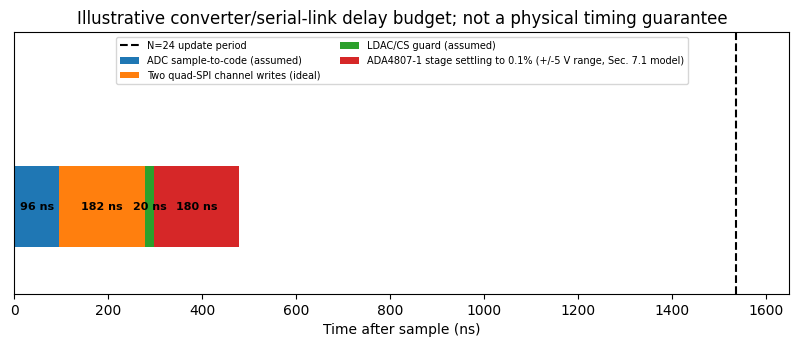

In [4]:
# Example timing budget. This is a model used for early planning, not a measured instrument delay.
Ts_fast = 64e-9
N = 24
fs_fast = 1/Ts_fast
fdac = fs_fast/N
f_spi = 66e6
clocks_per_write = (8+16)/4  # quad SDR instruction + 16 data bits
nclocks = 2*clocks_per_write
budget = {
    'ADC sample-to-code (assumed)': 96e-9,
    'Two quad-SPI channel writes (ideal)': nclocks/f_spi,
    'LDAC/CS guard (assumed)': 20e-9,
    'ADA4807-1 stage settling to 0.1% (+/-5 V range, Sec. 7.1 model)': 180e-9,
}
total = sum(budget.values())
print(f'FPGA fast sample: {Ts_fast*1e9:.0f} ns = {fs_fast/1e6:.3f} MHz')
print(f'Actuator period for N={N}: {N*Ts_fast*1e6:.3f} us = {fdac/1e3:.3f} kHz')
print(f'Ideal quad-SPI write: {nclocks:.0f} clocks @ {f_spi/1e6:.1f} MHz = {budget["Two quad-SPI channel writes (ideal)"]*1e9:.1f} ns')
print(f'Example sequential path: {total*1e9:.1f} ns = {total/Ts_fast:.2f} fast samples')
print('Unallocated time in update period: %.1f ns' % ((N*Ts_fast-total)*1e9))
fig,ax=plt.subplots(figsize=(10,3.4))
left=0
for name,duration in budget.items():
    x=duration*1e9
    ax.barh([0],[x],left=left,height=.42,label=name)
    ax.text(left+x/2,0,f'{x:.0f} ns',ha='center',va='center',fontsize=8,weight='bold')
    left+=x
ax.axvline(N*Ts_fast*1e9,color='k',ls='--',label='N=24 update period')
ax.set_xlim(0, max(1650,N*Ts_fast*1e9*1.05))
ax.set_ylim(-0.45, 0.9)
ax.set_yticks([]);ax.set_xlabel('Time after sample (ns)')
ax.set_title('Illustrative converter/serial-link delay budget; not a physical timing guarantee')
ax.legend(loc='upper center',fontsize=7,ncol=2)
plt.show()

### A logical timing sketch

The following sketch is only an **ordering diagram**, not a cycle-exact datasheet waveform:

```text
SCLK       |<-------- 2 input-register writes per chip -------->|  idle
CS_A_N     ____[U1 quad-SPI transaction(s)]_____________________high____
CS_B_N     ____[U2 quad-SPI transaction(s)]_____________________high____
DQ_A[3:0]  ----codes for OUT0, OUT1------------------------------idle----
DQ_B[3:0]  ----codes for OUT2, OUT3------------------------------idle----
LDAC_N     high-------------------------------------------------\__/----
VOUT0..3   old levels---------------------------------------------new----
```

**Critical distinction:** the datasheet's approximately **5 ns** figure is a typical delay from **LDAC falling edge to internal output update**; it is *not* a guarantee that four analog outputs from two physical devices settle within 5 ns of each other. Board-level simultaneous update skew and settling must be measured.

## 10. The output connector, cables, and load are part of the circuit

The prior reference drawing includes an **optional 49.9 Ohm series resistor**. This is useful only when its purpose is defined (for example source termination into a transmission line with an appropriate high-impedance far end). It is **not** automatically the correct way to connect an electrode driver, piezoelectric load, 50 Ohm instrument, or coaxial cable.

For a purely resistive load $R_L$ and series resistor $R_S$, the load voltage is

$$V_L = V_{\mathrm{AMP}}\frac{R_L}{R_L+R_S}.$$

With $R_L=R_S=50$ Ohm, the load receives **half** the amplifier's voltage (about $\pm 2.5$ V when the amplifier generates $\pm 5$ V). Trying to reach $\pm5$ V across 50 Ohm demands about **100 mA**. The ADA4807-1's linear output current is only about **50 mA (source) / 60 mA (sink)**, so a 50 Ohm load needs a separate line driver. The data sheet characterises the stage into **R_LOAD = 1 kOhm**, i.e. about 5 mA at full swing.

**Capacitive loads.** The ADA4807-1 shows about 17% overshoot driving 15 pF directly (ADA4807 data sheet). A cable or electrode capacitance therefore calls for an isolation resistor `R_ISO` outside the feedback node, sized and verified for that load.

**Action:** decide whether the real actuator looks like high impedance, a capacitor, a terminated transmission line, or an input to a separate high-voltage amplifier. Size the final output stage for that load, and keep the stage's extra dynamics inside the feedback-loop model.

If amplifier produces +5.0 V through 49.9 ohm series resistor:
  Rload (ohm)    Load V      Load current (mA)
          50       2.503         50.05
         100       3.336         33.36
        1000       4.762          4.76
       10000       4.975          0.50
     1000000       5.000          0.00


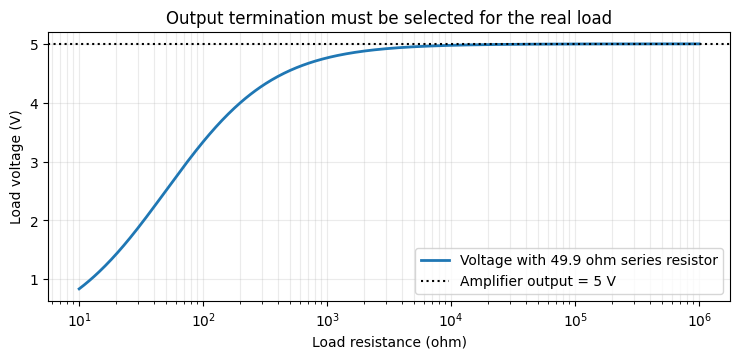

In [5]:
# Explore the load-divider mistake from the illustrative 49.9-ohm output part.
Vamp = 5.0
Rs = 49.9
loads = [50, 100, 1000, 10000, 1e6]
print(f'If amplifier produces +{Vamp:.1f} V through {Rs:.1f} ohm series resistor:')
print('  Rload (ohm)    Load V      Load current (mA)')
for rl in loads:
    vl = Vamp*rl/(Rs+rl)
    il = 1000*Vamp/(Rs+rl)
    print(f'  {rl:10.0f}     {vl:7.3f}       {il:7.2f}')
R = np.logspace(1,6,500)
fig,ax=plt.subplots(figsize=(8.8,3.5))
ax.semilogx(R,Vamp*R/(R+Rs),lw=2,label='Voltage with 49.9 ohm series resistor')
ax.axhline(Vamp,color='k',ls=':',label='Amplifier output = 5 V')
ax.set(xlabel='Load resistance (ohm)',ylabel='Load voltage (V)',
       title='Output termination must be selected for the real load')
ax.grid(alpha=.25,which='both');ax.legend();plt.show()

## 11. Resolution, noise, and speed: three different specifications

| Quantity | What it means | Consequence |
|---|---|---|
| **16 bits** | Static code granularity | An ideal 10 V span gives about **153 uV per LSB** |
| **0.1% settling** | Output reaches +/-0.1% of final step | For a 10 V full-scale step, 0.1% = **10 mV**, about 66 ideal LSBs. Data sheet: 100 ns (0-5 V range); this +/-5 V stage: about 180 ns (Section 7.1 model) |
| **Analog noise** | Noise from DAC, TIA, reference, supplies, and load | Can exceed or be below 1 LSB, depending on measurement bandwidth |
| **Data transfer time** | Shift register writes over quad-SPI | Often dominates start-to-update latency despite fast analog DAC |
| **16-bit settling** | Output settles to +/-0.5 LSB, for example | **Not established** by the 100 ns headline spec |

Noise is bandwidth-dependent. The datasheet's example rms noise figures are not automatically comparable to the full-bandwidth noise seen by an LQG loop sampled at 15.625 MHz. Likewise, the datasheet's nominal settling numbers are not measurements of this board's four-channel analog outputs.

In [6]:
span=10.0; lsb=span/(2**16)
for step in [0.1,1,10]:
    e=step*0.001  # 0.1 percent of step
    print(f'0.1% of a {step:g} V step = {e*1e3:.3f} mV = {e/lsb:.1f} ideal LSB')
print(f'For full-span 10 V, +/-0.5 LSB is +/-{lsb*1e6/2:.2f} uV')

0.1% of a 0.1 V step = 0.100 mV = 0.7 ideal LSB
0.1% of a 1 V step = 1.000 mV = 6.6 ideal LSB
0.1% of a 10 V step = 10.000 mV = 65.5 ideal LSB
For full-span 10 V, +/-0.5 LSB is +/-76.29 uV


## 12. Preliminary bill of materials (BOM) and design options

This is a **planning BOM**, not yet a quantity-priced or purchasing-ready BOM. Every capacitor voltage/dielectric, amplifier package, connector, and regulator must be checked for availability and power requirements.

| Ref. | Quantity | Item | Initial choice / function | Status |
|---|---:|---|---|---|
| U1-U2 | 2 | Dual 16-bit DAC | **AD3552R**, 32-pin LFCSP | Selected |
| U3-U6 | 4 | High-speed TIA | **ADA4807-1** (SOT-23-6 or SC70-6) | Manufacturer's characterisation amplifier; check DISABLE pin and load |
| U7 | 1 | External 2.5 V reference | **ADR4525** or internal AD3552R reference | Option; reference mode to be set |
| CCM0-CCM3 | 4 | VCM decoupling capacitor | **0.1 uF** from each VCM/(+) input node to ground | Data sheet Fig. 94 (no series resistor) |
| CFB0-CFB3 | 4 | Feedback capacitor | **8.2 pF NP0/C0G**, small footprint | Data sheet characterisation value; confirm on layout |
| RS0-RS3 | 4 | Output resistor footprints | **0 Ohm or optional 49.9 Ohm** | Fit after line/load design |
| DAC bypass | per pin | Ceramic capacitors | 100 nF, 1 uF on rail pins; caps on CVREF/PCAP/NCAP | Manufacturer topology; value/package check |
| TIA bypass | per amplifier | Ceramic + bulk | High-frequency local bypass near amplifier supplies | Finalise on PCB |
| Power | as needed | Regulators | +5 V (AVDD), +1.8 V, and **+/-5 V** for the amplifiers | **Part numbers TBD** |
| Connectors | as needed | Digital and analog I/O | FPGA header and chosen actuator connectors | **Pinout/load TBD** |

For each channel the **RFB2** element is **inside the AD3552R**, not an external BOM resistor: its physical *pin* closes the amplifier feedback loop.

## 13. PCB and signal integrity rules

1. **Analog feedback loop:** place each ADA4807-1 next to its `IOUTx` and `RFB2_x` pins (the AD3552R pinout puts one amplifier on each side of the chip, p. 68), with very short feedback traces. Keep `IOUTx` short and thin, since its capacitance adds to $C_{in}$ and slows settling. Use a small-footprint NP0 `C_FB`. Avoid vias and long stubs within the feedback path.
2. **Reference:** keep the 2.5 V reference quiet and route it away from SCLK/SDIO activity. Give it local bypassing as in the manufacturer design.
3. **Ground:** use a **continuous low-impedance ground plane**; connect AGND, DGND and exposed pad as the datasheet instructs. Do not split a return path under high-speed signal connections without a layout study.
4. **Supply bypassing:** place small HF capacitors at the IC pins, and route currents into the plane with short loops. Keep DVDD's fast switching return away from sensitive analog nodes.
5. **SPI:** plan common SCLK and LDAC fanout, realistic length matching/edge rate, individual CS/data lanes, and appropriate source damping if traces ring. Quad mode uses four bidirectional pin functions, even if code writes are the main activity.
6. **Analog outputs:** label op-amp output nodes separately from connector nodes after any optional series resistance. Design according to cable and load impedance.
7. **Testability:** expose ground-referenced test points on supplies, reference, LDAC, CS, SCLK, each IOUT/VCM as appropriate, and all four TIA outputs.
8. **Fault tolerance:** include an FPGA-driven global enable, deterministic reset/zero-code behaviour, and a way to disable the actuator outputs if reference or supply rails fail.
9. **Thermal:** consider op-amp dissipation when driving low impedances. Do not assume low-output-noise settings remain stable across full temperature range.

Manufacturer starting points: AD3552R datasheet **Figure 94 (application circuit and decoupling)**, **Figures 53-59 (ADA4807-1 test conditions)** and **Figure 96 / pp. 68-69 (layout)**. The final board needs CAD electrical-rule checks, IBIS or SPICE signal-integrity analysis where appropriate, and measurement.

## 14. Controller/firmware interface: block-level sequence

Below is **illustrative pseudocode**, not a tested FPGA register interface. It documents the sequence the hardware must perform and the state it must remember.

```text
power on with LDAC_N = 1, CS_A_N = CS_B_N = 1
wait until AVDD/DVDD/logic/reference are valid
reset both AD3552Rs
configure each device:
    select external 2.5-V reference if actually fitted
    set both ranges to bipolar +/-5 V  (register 0x19, 0x33)
    configure quad SPI and desired SDR/DDR behavior
    unmask both channels for hardware LDAC
    configure drive strength / errors as appropriate
    preload safe outputs to both input registers
pulse shared LDAC_N; verify expected safe level

on each actuator update boundary (every N = 24 FPGA samples):
    compute and clip the four actuator setpoints
    convert each requested voltage to a calibrated 16-bit DAC code
    load U1 CH0 + CH1 input registers via quad SPI
    in parallel, load U2 CH0 + CH1 via independent quad SPI lanes
    complete both SPI transactions; release both CS lines
    respect required setup/hold guard
    assert LDAC_N LOW once, then release HIGH
    record update timestamp and applied code in control model
    monitor both ALERT_N lines and trigger safe behavior on fault
```

**Important:** the sequence assumes staged **CHx_INPUT_16B** writes. Writing the live CHx_DAC registers, or leaving LDAC low, can produce output updates at different times. The actual RTL must document pulse widths, bit/endian ordering, and diagnostic readback.

## 15. Bring-up and validation plan

| Stage | Test | Expected result / acceptance criterion |
|---|---|---|
| 1. Power | No DACs fitted initially: check +5, +1.8, bipolar rails | Correct voltage, ripple, sequencing, current limits |
| 2. Reference | Measure reference and VCM pins | Clean 2.5 V domain; reference mode configured correctly |
| 3. SPI | Read chip ID/status and verify a harmless register write/readback | Reliable at **slow** SCLK before increasing speed |
| 4. Code-to-voltage | Request zero, quarter-scale, midscale and full-scale | Correct channel mapping, polarity, saturation and calibration |
| 5. LDAC | Write codes while LDAC high, then strobe low | No premature updates; four outputs update on shared pulse |
| 6. Analog load | Test with high-impedance oscilloscope first | No TIA oscillation, clipping or excessive DC offset |
| 7. Frequency | Step/impulse and sine sweeps on all outputs | Measure settling to 0.1%, 0.01% and tighter targets as needed |
| 8. Real cable | Connect *actual* cable/load or an accurate equivalent | No unstable ringing, attenuation surprises, or overheating |
| 9. Cross-chip sync | Simultaneous step; compare outputs on fast scope | **Measured** worst-case skew meets LQG timing requirement |
| 10. Loop closure | Test in HIL mode, initially with safe low gains | Stable measured closed loop, including quantified latency/jitter |
| 11. Robustness | Deliberately perturb supplies, gains and update timing | Stable or safe shutdown, with bounds documented |

**Recommended measurement:** capture the ADC sample-valid signal (or a proxy), SPI CS/SCLK, shared LDAC, and the four settled output voltages on one timebase. Report a latency distribution, **not** just a nominal sum of datasheet figures.

## 16. Open design decisions before a fabrication-ready circuit

**Must be answered before final schematic/PCB sign-off:**

- What is the **actuator input**: resistance, capacitance, cable type, required voltage/current, and isolation needs?
- Do outputs need **+/-5 V at the amplifier**, at the remote load, or at an electrode after another driver?
- Can the FPGA supply **1.8 V I/O** and two quad-SPI lane groups at the required clock with adequate timing margin?
- Is **about 180 ns to 0.1%** (+/-5 V range, Section 7.1 model) sufficient for the feedback requirement, or is a tighter output-error tolerance necessary?
- Does the manufacturer's **8.2 pF** feedback capacitor give the expected step response on the real layout (unknown `IOUT` and trace capacitance), and with the real load?
- Is the **+/-4.9 V** swing available from +/-5 V amplifier rails sufficient, or does the actuator need a separate higher-voltage stage?
- Do the reference source and regulators satisfy noise, tolerance, and power-up constraints?
- What are the expected maximum amplitude, slew rate and DC offset demanded by the LQG output during saddle stabilisation?
- How will FPGA code, reset, and regulator faults force outputs to a **known safe state**?

The existing PDF/PNG circuit sheets are therefore **reference drawings**. They need to be translated into an electrical-rule-checked CAD schematic and verified against the **exact package** and current datasheets prior to PCB manufacture.

## 17. Glossary

| Abbreviation | Meaning |
|---|---|
| ADC | Analog-to-Digital Converter |
| DAC | Digital-to-Analog Converter |
| FPGA | Field-Programmable Gate Array |
| LQG | Linear Quadratic Gaussian control |
| LQR | Linear Quadratic Regulator |
| HIL | Hardware-in-the-Loop simulation |
| TIA | Transimpedance Amplifier (current-to-voltage converter) |
| SPI / QSPI | Serial Peripheral Interface / quad-data-lane SPI |
| SCLK | Serial clock |
| CS | Chip select |
| LDAC | Hardware DAC latch/update strobe |
| SDR / DDR | Single / Double Data Rate |
| LSB | Least Significant Bit |
| RFB | On-chip DAC feedback-resistor selection pin |
| BOM | Bill of Materials |
| CFB | Feedback compensation capacitor (8.2 pF NP0 in the reference circuit) |
| VCM | Common-mode voltage |
| DNC | Do Not Connect |
| C0G / NP0 | Stable low-loss ceramic capacitor dielectric class |
| R_ISO | Isolation resistor between amplifier output and a capacitive load |
| GBW | Gain-bandwidth product of an op-amp |

## 18. Manufacturer documentation and linked design files

1. [Analog Devices AD3552R datasheet Rev. B (70 pages)](https://www.analog.com/media/en/technical-documentation/data-sheets/ad3552r.pdf). Particularly **Table 3 (AC characteristics, measured with the ADA4807-1), Table 4 (SPI timing), Figure 13 / Table 7 (pinout), Table 8 / Table 9 (span and RFB), Figures 53-59 (settling, slew rate and C_FB values), Figure 69 (TIA concept), DAC update mode (p. 37), Figure 94 (application circuit), Figure 96 (layout)**.
2. [ADA4807-1/ADA4807-2/ADA4807-4 amplifier datasheet](https://www.analog.com/media/en/technical-documentation/data-sheets/ADA4807-1_4807-2_4807-4.pdf). Supply range (2.7 V to 11 V), output swing and current, input capacitance, DISABLE pin, capacitive-load behaviour.
3. [EVAL-AD3552R evaluation-board user guide, Rev. C](https://www.analog.com/media/en/technical-documentation/user-guides/eval-ad3552r-ug-2217.pdf). Digital interface and supply design. Note that it describes +/-12 V supplies for the board's TIAs, beyond the ADA4807-1's limit, so its output stage is not the ADA4807-1 configuration used here; the values here come from the AD3552R data sheet's characterisation conditions.
4. [AD3552R product information and evaluation-board files](https://www.analog.com/en/products/ad3552r.html).
5. **`pylqg_tutorial.ipynb`**: Section 11 supplies the multirate architecture and latency model, and Section 12 puts this ADA4807-1 stage into the LQG plant model (small- and large-signal) and checks the closed loop's stability with it. The two circuit sheets are embedded above as attachments, so this notebook is self-contained.

### Final engineering conclusion

The **two AD3552R / four-TIA** approach is a plausible way to supply four synchronised bipolar analog outputs from a multirate FPGA controller. Its chief strengths are the fast dual-channel DAC architecture and common LDAC update semantics. With the manufacturer's ADA4807-1 stage the output path is now fully specified at reference-design level: a 26 ns first-order lag with 85-89 degrees of phase margin, about 180 ns to 0.1% in the +/-5 V range, and +/-4.9 V of swing. Its remaining risks are **the real load (current, capacitance), the unmeasured IOUT/layout capacitance, actual code-to-analog latency, FPGA interface timing, and safe actuator drive**. Resolve and measure those before regarding this as a final circuit.